# Worker voice in platform governance
Are algorithmic management appeals accessible and consequential for platform workers

**Project 12 · Target journal: Journal of Business Research · Reproducible results notebook**

Liang et al. (2025) develop a measure of perceived algorithmic control and relate it to work well-being and service performance. The article provides the theoretical framing for this secondary analysis of Fairwork reports. This study examines what organizations put in place when workers challenge a decision. Procedural justice motivates the distinction between filing an appeal, obtaining review, and seeking a remedy. Worker voice theory motivates separating individual appeals from collective representation.

**Sources**
- Liang et al. (2025), *Journal of Business Research*, article 115199. [DOI and publisher abstract](https://doi.org/10.1016/j.jbusres.2025.115199)
- [Fairwork Cloudwork Ratings 2023](https://fairwork.oii.ox.ac.uk/wp-content/uploads/sites/11/2023/07/Fairwork-Cloudwork-Ratings-2023-Red.pdf), especially pp. 12–15, 22 and 32–33.
- [Fairwork Cloudwork Ratings 2025](https://fairwork.oii.ox.ac.uk/wp-content/uploads/sites/11/2025/05/Fairwork-Cloudwork-Report-2025-FINAL.pdf), especially pp. 12–18, 21, 24–28, 30–33 and 41–42.
- [Fairwork's revision of the cloudwork criteria](https://fairwork.oii.ox.ac.uk/en/fw/blog/fairwork-updates-its-cloudwork-principles/). Threshold 4.1 added explicit documentation of prohibited conduct. The 5.1 rubric also changed.


## Research questions and planned publication exhibits

Each research question has one primary exhibit and three supporting exhibits.

| Research question | Primary manuscript exhibit | Supporting exhibits |
| --- | --- | --- |
| **RQ1.** Among repeat platforms, what changes in appeal procedures did Fairwork document between 2023 and 2025 despite unchanged due-process ratings? | **Figure 1.** Paired ratings alongside separately reported appeal changes | S1 Rating transitions and sample composition, S2 Feature-level change ledger, S3 Changes by appeal feature and rating |
| **RQ2.** How does reported appeal and review evidence differ by platform and decision context? | **Figure 2.** Decision-specific evidence and the 4.1 award by platform | S4 Feature coverage by decision type, S5 Within-platform contrasts, S6 Source ledger of decision-specific evidence |
| **RQ3.** What barriers do workers report, and how closely do the accounts align with documented procedures? | **Table 1.** Worker accounts and policy evidence side by side | S7 Evidence alignment, S8 Reported barriers by decision context, S9 Survey context |
| **RQ4.** How does Fairwork’s 4.1 award overlap with documented public recognition of organizing rights? | **Figure 3.** Joint distribution of individual due-process ratings and formal recognition | S10 Platform-level voice indicators, S11 Sensitivity to indicator definitions, S12 Recognition source ledger |

## Methodology

1. Retrieve the two public reports, verify the PDF fingerprints, and retain page locations. The reports are the empirical corpus. The anchor paper is used for scientific framing.
2. Extract the platform rosters and award lists directly from the PDFs. Harmonize Amazon Mechanical Turk and Scale/Remotasks names, then compare the 14 repeat platforms and 16 platforms in the 2025 roster.
3. Extract 4.1 and 5.1 awards from the editions' relevant narratives. Record 5.2 as unawarded only if the report explicitly states that no platform earned it. Apply the published scoring definitions as reported in each edition.
4. Read the report sections on Fair Pay, Fair Management, case profiles, and platform changes. Manually record page-anchored observations as paraphrases and keep scoring data, policy descriptions, and worker accounts in separate tables.
5. Answer RQ1 with a paired descriptive analysis. Code each distinct appeal feature described under 4.1 in the 2025 change log once per platform. Check the rubric revision before interpreting stable scores.
6. Answer RQ2 at the platform-by-decision level. Count an explicit feature only for its documented decision type. Track safeguards such as escrow separately from appeal or review. Mark cases without qualifying platform-specific evidence in the coded passages. Display the Fairwork 4.1 award alongside these cases as a separate benchmark.
7. Answer RQ3 by matching worker accounts to descriptions of procedures by platform, issue and, where available, incident period. Distinguish overlapping scope, co-reported mechanism and experience, and unmatched cases. Treat the survey figure as pooled context.
8. Answer RQ4 by cross-tabulating the 2025 due-process rating with separately documented formal recognition and checking a narrower bargaining definition. The sample is purposive, so use descriptive counts throughout.
9. Display and export the exhibits, verify file integrity, and package the outputs and their supporting data. The initial manual ledgers were checked against the cited passages and relevant adjacent sections in a retrospective source audit. The audit changed the collective recognition result and refined wording for worker accounts. An independent coding pass, agreement assessment and adjudication are pending.

In [11]:
# Step 1 · Set up the Kaggle runtime
# Configure source and output paths, install the PDF reader only if needed, and prepare plotting defaults.

import hashlib
import io
import platform
from importlib.metadata import version
import json
import os
import re
import shutil
import subprocess
import sys
import textwrap
import zipfile
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import FileLink, HTML, Image, display
from matplotlib.colors import BoundaryNorm, ListedColormap

try:
    from pypdf import PdfReader
except ModuleNotFoundError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "pypdf==5.9.0"])
    from pypdf import PdfReader

KAGGLE = Path("/kaggle/working").is_dir()
WORK = Path("/kaggle/working") if KAGGLE else Path.cwd()
RESULT_ROOT = WORK / "project12_fairwork_results"
SOURCE_CACHE = (Path("/kaggle/temp") if KAGGLE else WORK) / "project12_source_cache"
SOURCE_CACHE.mkdir(parents=True, exist_ok=True)
for folder in ("figures", "tables", "plot_data", "provenance"):
    (RESULT_ROOT / folder).mkdir(parents=True, exist_ok=True)
WRITTEN = set()
EXHIBITS = {}
mpl.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10, "axes.labelcolor": "#172730",
    "text.color": "#172730", "axes.edgecolor": "#BAC6CD", "pdf.fonttype": 42,
    "figure.facecolor": "white", "savefig.facecolor": "white",
})


In [2]:
# Step 2 · Acquire and authenticate the source reports
# Locate attached or cached PDFs, download missing inputs, and validate their fingerprints and page counts.

SOURCES = {
    2023: {
        "name": "Fairwork-Cloudwork-Ratings-2023-Red.pdf",
        "url": "https://fairwork.oii.ox.ac.uk/wp-content/uploads/sites/11/2023/07/Fairwork-Cloudwork-Ratings-2023-Red.pdf",
        "sha256": "d1fecc0d7f39cc523f471c49895c6f86572045bc015215a3654437969424316b",
        "pages": 40,
    },
    2025: {
        "name": "Fairwork-Cloudwork-Report-2025-FINAL.pdf",
        "url": "https://fairwork.oii.ox.ac.uk/wp-content/uploads/sites/11/2025/05/Fairwork-Cloudwork-Report-2025-FINAL.pdf",
        "sha256": "5a12e5c6c666fbae1471e22277ff8aee65f6c52ead3309659a03f861fe8305d1",
        "pages": 48,
    },
}

def verified(pdf, source):
    return (
        pdf.is_file()
        and hashlib.sha256(pdf.read_bytes()).hexdigest() == source["sha256"]
    )

def acquire(edition, source):
    local_dir = Path(os.environ.get("FAIRWORK_INPUT_DIR", "."))
    cache = SOURCE_CACHE / source["name"]
    candidates = [local_dir / source["name"], local_dir / f"fairwork{edition}.pdf", cache]
    if KAGGLE:
        candidates.extend(sorted(Path("/kaggle/input").rglob(source["name"])))
    for candidate in candidates:
        if verified(candidate, source):
            return candidate
    pending = cache.with_suffix(".part")
    try:
        request = Request(source["url"], headers={"User-Agent": "Fairwork research replication/1.0"})
        with urlopen(request, timeout=90) as response, pending.open("wb") as target:
            shutil.copyfileobj(response, target)
        if not verified(pending, source):
            raise ValueError(f"The {edition} download differs from the stated PDF fingerprint.")
        pending.replace(cache)
        return cache
    except (OSError, ValueError) as error:
        raise RuntimeError(f"Supply the original {edition} PDF or enable Kaggle Internet.") from error
    finally:
        pending.unlink(missing_ok=True)

readers = {}
for edition, source in SOURCES.items():
    path = acquire(edition, source)
    readers[edition] = PdfReader(path)
    assert len(readers[edition].pages) == source["pages"]
    print(f"{edition}: verified {source['pages']} pages against the declared SHA-256.")

def page_text(edition, printed_page):
    # Printed and physical page numbers match on all of the referenced pages.
    text = readers[edition].pages[printed_page - 1].extract_text()
    return re.sub(r"\s+", " ", text.replace("\u00ad", "")).strip()

sources = pd.DataFrame(
    [{"Edition": year, "Filename": meta["name"], "Pages": meta["pages"],
      "SHA-256": meta["sha256"], "Source URL": meta["url"]}
     for year, meta in SOURCES.items()]
)


2023: verified 40 pages against the declared SHA-256.
2025: verified 48 pages against the declared SHA-256.


In [12]:
# Step 3 · Extract platform rosters and awards from the reports
# Read relevant PDF pages, harmonize platform names, check extraction, and construct paired and 2025 samples.

def canonical(name):
    fixed = {
        "amt": "Amazon Mechanical Turk",
        "mturk": "Amazon Mechanical Turk",
        "scale/remotasks": "Remotasks",
        "soyfreelancer": "SoyFreelancer",
        "peopleperhour": "PeoplePerHour",
    }
    return fixed.get(name.strip().casefold(), name.strip())

raw_roster_23 = readers[2023].pages[14].extract_text()
roster_23 = {
    canonical(line) for line in re.search(r"Page 15\s+(.*?)Principle 1", raw_roster_23, re.S)[1].splitlines()
    if line.strip()
}
raw_roster_25 = readers[2025].pages[15].extract_text()
roster_25 = {
    canonical(match[1]) for line in raw_roster_25.splitlines()
    if (match := re.fullmatch(r"([A-Za-z][A-Za-z ]+?)\s+[0-9]", line.strip()))
}
rosters = {2023: roster_23, 2025: roster_25}

def list_names(fragment):
    return {
        canonical(name) for name in re.split(r",|\band\b", fragment, flags=re.I)
        if name.strip()
    }

due_awards = {
    edition: list_names(re.search(
        r"met all our criteria for (?:principle )?threshold 4\.1\.\s*(.*?)\s+had policies",
        page_text(edition, pg), re.I,
    )[1])
    for edition, pg in {2023: 13, 2025: 14}.items()
}
representation_awards = {
    2023: list_names(re.search(
        r"awarded this point \(([^)]+)\)", page_text(2023, 13), re.I
    )[1]),
    2025: list_names(re.search(
        r"in six platforms \(([^)]+)\)", page_text(2025, 15), re.I
    )[1]),
}
for edition, pg in {2023: 14, 2025: 15}.items():
    assert re.search(r"unable to award this point to any plat", page_text(edition, pg), re.I)
assert (len(roster_23), len(roster_25), len(roster_23 & roster_25)) == (15, 16, 14)
assert (len(due_awards[2023]), len(due_awards[2025])) == (6, 8)
assert (len(representation_awards[2023]), len(representation_awards[2025])) == (2, 6)
for edition, names in rosters.items():
    assert due_awards[edition] <= names and representation_awards[edition] <= names

ratings = pd.DataFrame([
    {"Edition": edition, "Platform": name, "4.1 awarded": int(name in due_awards[edition]),
     "5.1 awarded": int(name in representation_awards[edition]), "5.2 awarded": 0,
     "Ratings page": 15 if edition == 2023 else 16,
     "4.1 narrative page": 13 if edition == 2023 else 14,
     "5.1 narrative page": 13 if edition == 2023 else 15}
    for edition, members in rosters.items() for name in sorted(members)
])
ratings_25 = ratings[ratings["Edition"] == 2025].copy()
paired = ratings.pivot(index="Platform", columns="Edition", values="4.1 awarded").dropna()
paired = paired.astype(int).rename(columns={2023: "4.1 in 2023", 2025: "4.1 in 2025"})
paired.index.name = "Platform"

print(f"2023: {len(roster_23)} platforms. 2025: {len(roster_25)} platforms. Paired: {len(paired)}.")


2023: 15 platforms. 2025: 16 platforms. Paired: 14.


## Page-anchored evidence ledgers

The ledgers contain paraphrases of the Fairwork reports. In the RQ1 change log, the four feature categories distinguish a stated grounds rule, a route to an explanation after a decision, a procedural rule, and the means to find or submit an appeal. A platform can appear in more than one category. In RQ2, general disciplinary policies are included only where the report ties them to a named decision or explicitly covers access after deactivation. Client and platform actions are kept distinct in the RQ3 ledger. For RQ4, explicit bargaining language is a narrower coding rule applied to the cited 2025 passages.

### Coding rules for review

- **RQ1.** Use Fairwork’s 2025 change log, pp. 30–33. For each repeat platform, code each distinct change feature once. Compare the reported 4.1 award status under each edition’s rubric.
- **RQ2.** Extract platform-specific evidence from the Fair Pay and Fair Management narratives, platform profiles, change log and relevant worker accounts. Code the named decision and feature with a page reference. Use **appeal or review** for an explicit route to challenge the decision or a named review or mediation actor. Use **safeguard only** for prevention or correction, such as escrow or a chance to redo work, when an appeal or review is uncoded. Record general support tickets in worker accounts as reported interactions. The appeal category requires evidence of a challenge or review mechanism for the named decision. Record no qualifying passage as **no coded mention**. Record rubric-based evidence separately.
- **RQ3.** Code the narrator’s reported experience and the scope of any cited procedure. Record the parties, decision, available timing and pages. Use **overlapping scope** for a partial or general fit, **co-reported** when the mechanism and experience appear in the same account, and **unmatched** when the corpus provides no corresponding procedure for the episode. A test of policy implementation would also require an independently documented policy in force at the incident date.
- **RQ4.** Code a platform’s public statement recognizing organizing rights if the 2025 report describes it in the representation narrative, platform profiles or change log. Record explicit reference to bargaining or collective agreements separately. Keep older report language outside the 2025 indicator unless the 2025 report explicitly repeats it. Keep third-party mediation distinct from a platform’s own public recognition statement. Record Fairwork awards as reported and retain the page for each public statement.

### Source audit

The audit checks existing entries and cross-checks the representation narrative against the platform profiles and change log. The archived `provenance/evidence_source_audit.csv` records the reviewed sections, corrections and decisions about borderline evidence. The audit is a retrospective check informed by the existing coding.

For independent review, apply the rules to the source passages before comparing with the existing ledgers. Log differences in evidence inclusion, decision or feature classification, policy match and source reference. Retain the initial judgments and the resolved coding so the final counts can be traced.

In [13]:
# Step 4 · Load the evidence coding and audit references
# Load the page-anchored manual coding for all four RQs and check platform membership, keys and source pages.

LEDGER_TEXT = {'changes': 'Platform|Feature|Page|Evidence\n'
            'Elharefa|Appeal procedure|30|Added an appeal procedure to its terms.\n'
            'Elharefa|Decision-specific explanation|30|Specified email or account dashboard notification of '
            'reasons for disciplinary action.\n'
            'Prolific|Appeal intake and visibility|32|Made appeal instructions easier to find and added form '
            'and chatbot intake.\n'
            'Prolific|Rules and grounds|32|Revised the published grounds for taking disciplinary action.\n'
            'Remotasks|Appeal intake and visibility|31|Introduced a support route for deactivation and '
            'disciplinary appeals.\n'
            'Remotasks|Decision-specific explanation|31|Described how workers can request more information '
            'about discipline.\n'
            'SoyFreelancer|Appeal procedure|33|Added an appeal section to its terms.\n'
            'SoyFreelancer|Appeal intake and visibility|33|Publicized appeal instructions and the support '
            'channel in its newsletter.\n'
            'Terawork|Appeal procedure|32|Updated its terms to describe disciplinary appeals and added a '
            'dispute section.\n',
 'safeguards': 'Platform|Decision|Feature|Page|Evidence\n'
               'Remotasks|Account suspension|Appeal route|31|Introduced deactivation support for '
               'disciplinary challenges.\n'
               'Remotasks|Account suspension|Reason or explanation route|31|Deactivation support also '
               'describes obtaining further explanations.\n'
               'Translated|Account suspension|Appeal route|18|The report describes appeals by email and '
               'access to policy information after deactivation.\n'
               'Translated|Account suspension|Access after lockout|18|Deactivated workers can access the '
               'published procedure.\n'
               'Fiverr|Task rejection|Appeal route|14|Fairwork identifies customer support and order dispute '
               'instructions for work rejections.\n'
               'Elharefa|Task rejection|Appeal route|17|The report describes a dispute procedure for '
               'rejected work.\n'
               'Elharefa|Task rejection|Named review or mediation actor|17|The company team mediates '
               'disputes over rejected work.\n'
               'Elharefa|Task rejection|Correction or remedy option|30|Workers may revise or redo delivered '
               'work at least once upon the client’s request.\n'
               'Terawork|Task rejection|Correction or remedy option|31|Workers can request at least one '
               'revision of rejected work.\n'
               "Fiverr|Nonpayment|Payment protection|25|The Fairwork worker profile describes the platform's "
               'escrow facility.\n'
               'ComeUp|Nonpayment|Payment protection|12|The report identifies escrow among protections for '
               'completed work.\n'
               'Clickworker|Nonpayment|Payment protection|12|The report identifies escrow among protections '
               'for completed work.\n'
               'Elharefa|Nonpayment|Payment protection|12|The report identifies escrow among protections for '
               'completed work.\n'
               'Prolific|Nonpayment|Payment protection|12|The report identifies escrow among protections for '
               'completed work.\n'
               'SoyFreelancer|Nonpayment|Payment protection|12|The report identifies escrow among '
               'protections for completed work.\n'
               'Terawork|Nonpayment|Payment protection|12|The report identifies escrow among protections for '
               'completed work.\n'
               'Translated|Nonpayment|Payment protection|12|The report identifies escrow among protections '
               'for completed work.\n',
 'worker_cases': 'Case|Edition|Platform|Decision|Mechanism page|Worker page|Match|Barrier|Mechanism '
                 'evidence|Worker evidence\n'
                 'C01|2023|Fiverr|Task rejection and nonpayment|13|22|Overlapping scope|No '
                 'intervention|Fairwork describes a support route for objections to rejected work.|A worker '
                 'described an order dispute with withheld payment. Support deferred to negotiation with the '
                 'client and the worker reported receiving nothing.\n'
                 'C02|2025|Fiverr|Account suspension|14|25|Overlapping scope|Lack of an explanation|Fairwork '
                 'describes disciplinary appeals and contact with a human representative for platforms that '
                 'received 4.1.|A worker described sudden account suspensions or removal of service listings '
                 'without clear explanations. The account describes a general pattern.\n'
                 'C03|2025|Fiverr|Client dispute|25|25|Co-reported mechanism and experience|Slow or '
                 'impersonal review|The worker story identifies a formal platform mediation channel.|The '
                 'account described slow or impersonal resolution and raised concerns about bias. The report '
                 'gives no case-level success rate.\n'
                 'C04|2025|Appen|Delayed payment||26|Unmatched|Automated acknowledgement|The worker account '
                 'establishes that a ticket channel was used. No separately matched payment appeal policy is '
                 'coded.|After the August 2024 CrowdGen migration, the worker received automated replies to '
                 'repeated tickets. The worker reported receiving payment two weeks later.\n'
                 'C05|2025|Appen|Client-platform deactivation||27|Unmatched|Lack of an explanation|A support '
                 'request was filed. The decision was made on a client platform and a matching review policy '
                 'was not located in the report.|The worker reported a September 2024 deactivation and '
                 'received a generic list of potential grounds. Four months later, the worker still had no '
                 'result from the investigation or specific reason.\n'
                 'C06|2025|Elharefa|Client dispute|17|28|Overlapping scope|Perceived lack of effective '
                 'recourse|Fairwork describes a new team-mediated process for rejected work.|A worker '
                 'questioned the effectiveness of dispute resolution. The report does not link that account '
                 'to a rejected-work case after the policy change.\n',
 'recognition': 'Platform|Page|Organizing recognized|Bargaining explicitly referenced|Evidence\n'
                "Appen|15|1|0|Fairwork identifies freedom of association in the platform's modern slavery "
                'policy. This passage does not explicitly attribute bargaining language to Appen.\n'
                'ComeUp|32|1|0|Terms acknowledge the right of workers to organize.\n'
                'Creative Words|15|1|0|Fairwork reports that the company previously issued a similar public '
                'statement on organizing rights.\n'
                'Elharefa|31|1|1|Terms add a public commitment to freedom of association and collective '
                'bargaining.\n'
                'Translated|33|1|1|Public statement refers to freedom of association and collective '
                'agreements.\n'
                "Upwork|15|1|0|Fairwork identifies freedom of association in the platform's modern slavery "
                'policy. This passage does not spell out bargaining language.\n'
                'SoyFreelancer|33|1|0|The change log records a statement recognizing freedom of association '
                'and noting support for workers to organize collectively.\n'}

def load_ledger(name):
    return pd.read_csv(io.StringIO(LEDGER_TEXT[name]), sep="|", keep_default_na=False)

changes = load_ledger("changes")
safeguards = load_ledger("safeguards")
worker_cases = load_ledger("worker_cases")
recognition = load_ledger("recognition")
assert set(changes["Platform"]) <= set(paired.index)
assert set(safeguards["Platform"]) <= roster_25
assert set(recognition["Platform"]) <= roster_25
assert not changes.duplicated(["Platform", "Feature"]).any()
assert not safeguards.duplicated(["Platform", "Decision", "Feature"]).any()
assert not worker_cases["Case"].duplicated().any()
assert not recognition["Platform"].duplicated().any()
assert recognition["Organizing recognized"].eq(1).all()
assert recognition["Bargaining explicitly referenced"].isin([0, 1]).all()

for frame in (changes, safeguards, recognition):
    for row in frame.itertuples(index=False):
        assert 1 <= row.Page <= SOURCES[2025]["pages"] and page_text(2025, row.Page)
for row in worker_cases.to_dict("records"):
    assert row["Platform"] in rosters[row["Edition"]]
    for column in ("Worker page", "Mechanism page"):
        if row[column] != "":
            assert page_text(row["Edition"], int(row[column]))

# Check the number of change-log entries against the source section.
assert set(changes["Page"]) == {30, 31, 32, 33}
assert sum(page_text(2025, page).count("4.1") for page in (30, 31, 32, 33)) == changes["Platform"].nunique()
assert re.search(r"40\s*%\s+of workers were not aware", page_text(2025, 21), re.I)
print(f"Loaded {len(changes)} changes, {len(safeguards)} decision-specific features, "
      f"{len(worker_cases)} worker accounts or episodes, and {len(recognition)} recognition entries.")


Loaded 9 changes, 17 decision-specific features, 6 worker accounts or episodes, and 7 recognition entries.


In [14]:
# Step 5 · Set up publication exports
# Define reproducible tables, figure styles, previews, and source manifest exports before computing results.

def remember(path):
    WRITTEN.add(path)
    return path

def csv_export(frame, folder, name):
    target = RESULT_ROOT / folder / f"{name}.csv"
    frame.to_csv(target, index=False, encoding="utf-8")
    remember(target)
    return target

def exhibit_table(identifier, slug, title, frame, note):
    EXHIBITS[identifier] = (title, note)
    csv_export(frame, "tables", f"{identifier}_{slug}")
    display(HTML(
        f"<h4>{identifier}. {title}</h4>"
        f"<div style='overflow-x:auto; overflow-wrap:break-word'>{frame.to_html(index=False, escape=True, na_rep='', justify='left')}</div>"
        f"<p><em>{note}</em></p>"
    ))

def exhibit_figure(identifier, slug, title, fig, plot_data, note):
    EXHIBITS[identifier] = (title, note)
    stem = f"{identifier}_{slug}"
    for ext in ("pdf", "png"):
        path = RESULT_ROOT / "figures" / f"{stem}.{ext}"
        fig.savefig(path, dpi=300, bbox_inches="tight")
        remember(path)
    csv_export(plot_data, "plot_data", stem)
    display(HTML(f"<h4>{identifier}. {title}</h4>"))
    display(Image(filename=str(RESULT_ROOT / "figures" / f"{stem}.png"), width=720))
    display(HTML(f"<p><em>{note}</em></p>"))
    plt.close(fig)

def labeled_matrix(data, labels, palette, width, height, axis_x="", axis_y=""):
    fig, ax = plt.subplots(figsize=(width, height), layout="constrained")
    n_colors = len(palette)
    ax.imshow(data, cmap=ListedColormap(palette),
              norm=BoundaryNorm(np.arange(n_colors + 1) - .5, n_colors), aspect="auto")
    ax.set_xticks(np.arange(data.shape[1]), data.columns, fontsize=9)
    ax.set_yticks(np.arange(data.shape[0]), data.index, fontsize=9)
    ax.xaxis.tick_top()
    ax.xaxis.set_label_position("top")
    ax.set_xlabel(axis_x, labelpad=11)
    ax.set_ylabel(axis_y)
    ax.tick_params(which="both", length=0, pad=6)
    ax.set_xticks(np.arange(data.shape[1] + 1) - .5, minor=True)
    ax.set_yticks(np.arange(data.shape[0] + 1) - .5, minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    for spine in ax.spines.values():
        spine.set_visible(False)
    for row in range(data.shape[0]):
        for col in range(data.shape[1]):
            value = data.iloc[row, col]
            dark = value == n_colors - 1
            ax.text(col, row, labels[row, col], ha="center", va="center",
                    color="white" if dark else "#172730", fontsize=9,
                    fontweight="bold" if value else "normal")
    return fig

csv_export(sources, "provenance", "source_manifest")
csv_export(ratings, "provenance", "report_extracted_ratings")
runtime = {
    "Python": platform.python_version(),
    **{package: version(package) for package in ("pypdf", "numpy", "pandas", "matplotlib", "ipython")},
}
environment = remember(RESULT_ROOT / "provenance" / "run_environment.json")
environment.write_text(json.dumps(runtime, indent=2) + "\n", encoding="utf-8")
requirements = remember(RESULT_ROOT / "provenance" / "requirements.txt")
requirements.write_text(
    "".join(f"{package}=={installed}\n" for package, installed in runtime.items() if package != "Python"),
    encoding="utf-8",
)
audit = pd.DataFrame([
    ("RQ1", "2025", "30–33", "Retained classifications and refined wording",
     "Five platform sections contain 4.1 changes. Page 30 specifies email or dashboard notification of disciplinary reasons."),
    ("RQ2", "2025", "14, 17–18, 30–31", "Clarified the Elharefa revision safeguard",
     "Elharefa’s company team mediates rejected-work disputes. Its revision or redo clause on page 30 is triggered by a client request."),
    ("RQ2", "2025", "12, 25–28", "Retained the nonpayment classifications",
     "Escrow is a safeguard. The Appen payment account describes ticket use for delayed payment. The Elharefa account discusses general dispute channels without identifying a platform-specific nonpayment appeal."),
    ("RQ2", "2025", "14, 29, 41", "Retained the separate 4.1 benchmark",
     "The rubric requires appeals for disciplinary actions and work rejections. The Clickworker ombuds passage documents general mediation without identifying one of the three coded decisions."),
    ("RQ3", "2023", "13, 22", "Retained overlapping scope for C01",
     "Fiverr’s description covers appeals of rejected work. The worker also reports withheld payment. The passages do not establish the policy version in force for the episode."),
    ("RQ3", "2025", "14, 25", "Clarified C02 and retained C03",
     "The Fiverr profile describes suspensions and gig removals as a pattern. The mediation mechanism and the reported experience appear in the same profile."),
    ("RQ3", "2025", "26–27", "Added reported timing for C04 and C05",
     "August 2024 dates the platform migration. September 2024 dates the client-platform deactivation. These dates do not establish which policy applied."),
    ("RQ3", "2025", "17, 28", "Retained overlapping scope for C06",
     "The platform profile describes new mediation for rejected work. The worker’s comments do not identify an episode under that procedure."),
    ("RQ4", "2025", "15, 17–18, 29, 31–33", "Added SoyFreelancer recognition",
     "Page 33 documents a public statement of association rights and support for organizing. Fairwork’s overall 5.1 award list on page 15 omits SoyFreelancer. The two indicators therefore differ."),
    ("RQ4", "2023 and 2025", "2023: 13; 2025: 15, 31–33", "Retained the 2025 explicit bargaining definition",
     "The 2023 report quotes Upwork on bargaining. The 2025 passage mentions association only, so the earlier language is outside the 2025 definition."),
], columns=["Question", "Edition", "Report pages", "Audit outcome", "Rationale"])
csv_export(audit, "provenance", "evidence_source_audit")
print("Wrote the source manifest, evidence audit, extracted ratings and runtime versions.")


Wrote the source manifest, evidence audit, extracted ratings and runtime versions.


## RQ1 Changes missed by unchanged aggregate ratings

The paired unit is the platform. Figure 1 compares awarded status under each edition’s rubric with the appearance of any appeal-related 4.1 entry in the 2025 change log. S1 shows the effect of changes in the platforms covered by the two editions. S2 and S3 document the feature-level evidence.

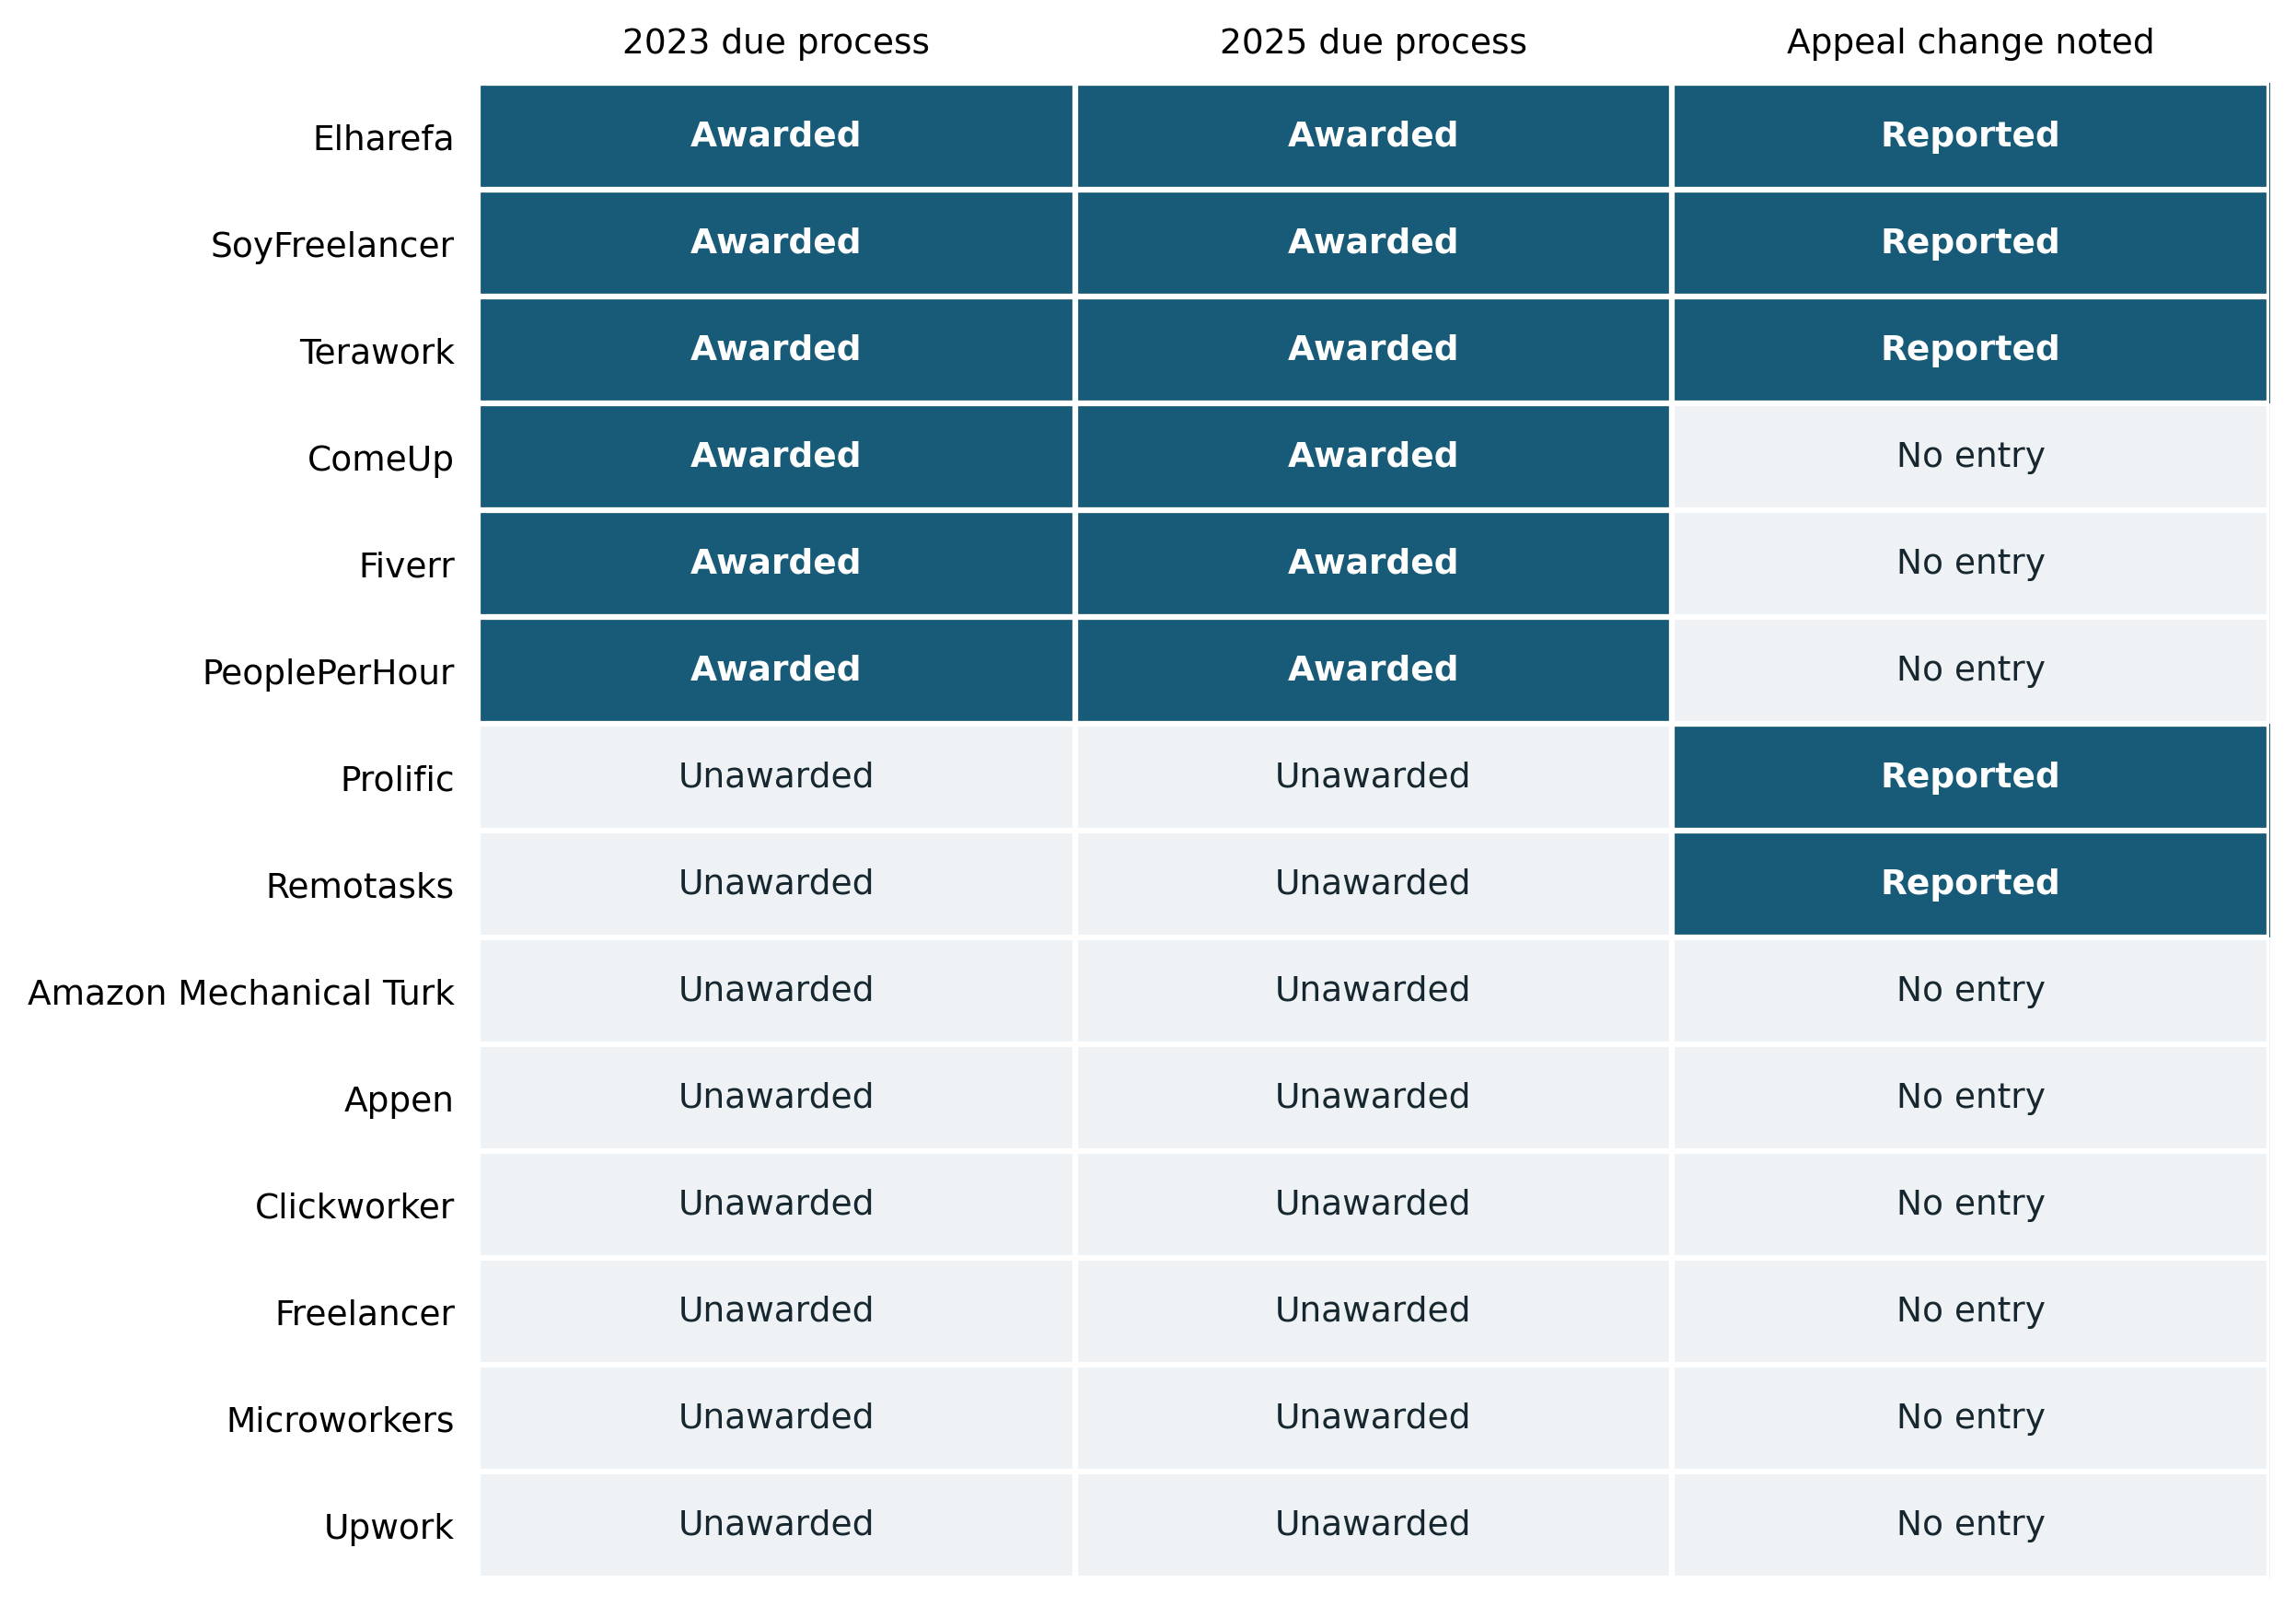

Sample,Platforms,Awarded 2023,Awarded 2025,Reported 4.1 change
All rated in 2023,15,6,,
All rated in 2025,16,,8,
2023-only platforms,1,0,,
2025-only platforms,2,,2,
Paired: 0 to 0,8,0,0,2
Paired: 1 to 1,6,6,6,3


Platform,Feature,Page,Evidence,4.1 in 2025
Elharefa,Appeal procedure,30,Added an appeal procedure to its terms.,1
Elharefa,Decision-specific explanation,30,Specified email or account dashboard notification of reasons for disciplinary action.,1
Prolific,Appeal intake and visibility,32,Made appeal instructions easier to find and added form and chatbot intake.,0
Prolific,Rules and grounds,32,Revised the published grounds for taking disciplinary action.,0
Remotasks,Appeal intake and visibility,31,Introduced a support route for deactivation and disciplinary appeals.,0
Remotasks,Decision-specific explanation,31,Described how workers can request more information about discipline.,0
SoyFreelancer,Appeal procedure,33,Added an appeal section to its terms.,1
SoyFreelancer,Appeal intake and visibility,33,Publicized appeal instructions and the support channel in its newsletter.,1
Terawork,Appeal procedure,32,Updated its terms to describe disciplinary appeals and added a dispute section.,1


4.1 in 2025,Feature,Unawarded,Awarded
,Appeal intake and visibility,2,1
,Appeal procedure,0,3
,Decision-specific explanation,1,1
,Rules and grounds,1,0


In [15]:
# Step 6 · Analyze the paired reports for RQ1
# Align platform editions, identify which stable ratings have policy changes, and generate Figure 1 and S1–S3.

paired["A change reported"] = paired.index.isin(changes["Platform"]).astype(int)
paired["Features reported"] = paired.index.map(changes.groupby("Platform")["Feature"].nunique()).fillna(0).astype(int)
f1 = paired.sort_values(["4.1 in 2025", "A change reported", "Platform"],
                        ascending=[False, False, True])
f1_display = f1.iloc[:, :3].rename(columns={
    "4.1 in 2023": "2023 due process", "4.1 in 2025": "2025 due process",
    "A change reported": "Appeal change noted",
})
f1_labels = np.column_stack([
    np.where(f1.iloc[:, 0] == 1, "Awarded", "Unawarded"),
    np.where(f1.iloc[:, 1] == 1, "Awarded", "Unawarded"),
    np.where(f1.iloc[:, 2] == 1, "Reported", "No entry"),
])
fig = labeled_matrix(f1_display, f1_labels, ["#EEF2F4", "#175B78"], 8.2, 5.7)
exhibit_figure("Figure_1", "paired_ratings_and_changes",
               "Appeal changes among platforms rated in both editions",
               fig, f1.reset_index(),
               "Fairwork rated 14 platforms in both editions. No entry means no coded 4.1 change in the 2025 change log.")

paired_counts = (paired.groupby(["4.1 in 2023", "4.1 in 2025"], as_index=False)
                 .agg(Platforms=("A change reported", "size"), With_reported_change=("A change reported", "sum")))
s1 = pd.DataFrame([
    {"Sample": "All rated in 2023", "Platforms": len(roster_23),
     "Awarded 2023": len(due_awards[2023]), "Awarded 2025": "", "Reported 4.1 change": ""},
    {"Sample": "All rated in 2025", "Platforms": len(roster_25),
     "Awarded 2023": "", "Awarded 2025": len(due_awards[2025]), "Reported 4.1 change": ""},
    {"Sample": "2023-only platforms", "Platforms": len(roster_23 - roster_25),
     "Awarded 2023": len(due_awards[2023] - roster_25), "Awarded 2025": "", "Reported 4.1 change": ""},
    {"Sample": "2025-only platforms", "Platforms": len(roster_25 - roster_23),
     "Awarded 2023": "", "Awarded 2025": len(due_awards[2025] - roster_23), "Reported 4.1 change": ""},
] + [
    {"Sample": f"Paired: {old} to {new}", "Platforms": int(count),
     "Awarded 2023": int(old * count), "Awarded 2025": int(new * count),
     "Reported 4.1 change": int(with_change)}
    for (old, new), (count, with_change) in
    paired_counts.set_index(["4.1 in 2023", "4.1 in 2025"]).iterrows()
])
exhibit_table("S1", "sample_and_transitions", "Sample composition and due-process transitions", s1,
              "0 = unawarded and 1 = awarded. Empty cells mark years or comparisons outside the row's sample.")
s2 = changes.merge(paired.reset_index()[["Platform", "4.1 in 2025"]], on="Platform", validate="many_to_one")
exhibit_table("S2", "appeal_change_ledger", "Page-anchored appeal changes reported in 2025", s2,
              "Features are coded from the 2025 change log. Page numbers refer to the printed report.")
s3 = (s2.groupby(["Feature", "4.1 in 2025"]).size().unstack(fill_value=0)
      .reindex(columns=[0, 1], fill_value=0)
      .rename(columns={0: "Unawarded", 1: "Awarded"}).reset_index())
exhibit_table("S3", "appeal_change_features", "Types of documented changes by 2025 rating", s3,
              "Counts are platform–feature entries. One platform may contribute to multiple feature categories.")


## RQ2 Appeals by decision type

Figure 2 reports platform-specific passages for suspension or deactivation, task rejection, and nonpayment. A documented appeal route or named review actor takes priority over safeguards such as escrow or a chance to redo work. **No coded mention** means no qualifying platform-specific evidence was entered for that decision.

The separate award column shows the overall Fairwork 4.1 assessment. The 2025 rubric requires documented routes to challenge disciplinary actions and work rejections (p. 41). It lists nonpayment among punitive actions for which workers should receive an explanation. An award records Fairwork’s assessment against that rubric. The decision columns record what the coded passages explicitly describe. S4 shows their overlap, including how many awarded platforms have an explicitly coded route or reviewer for each decision.


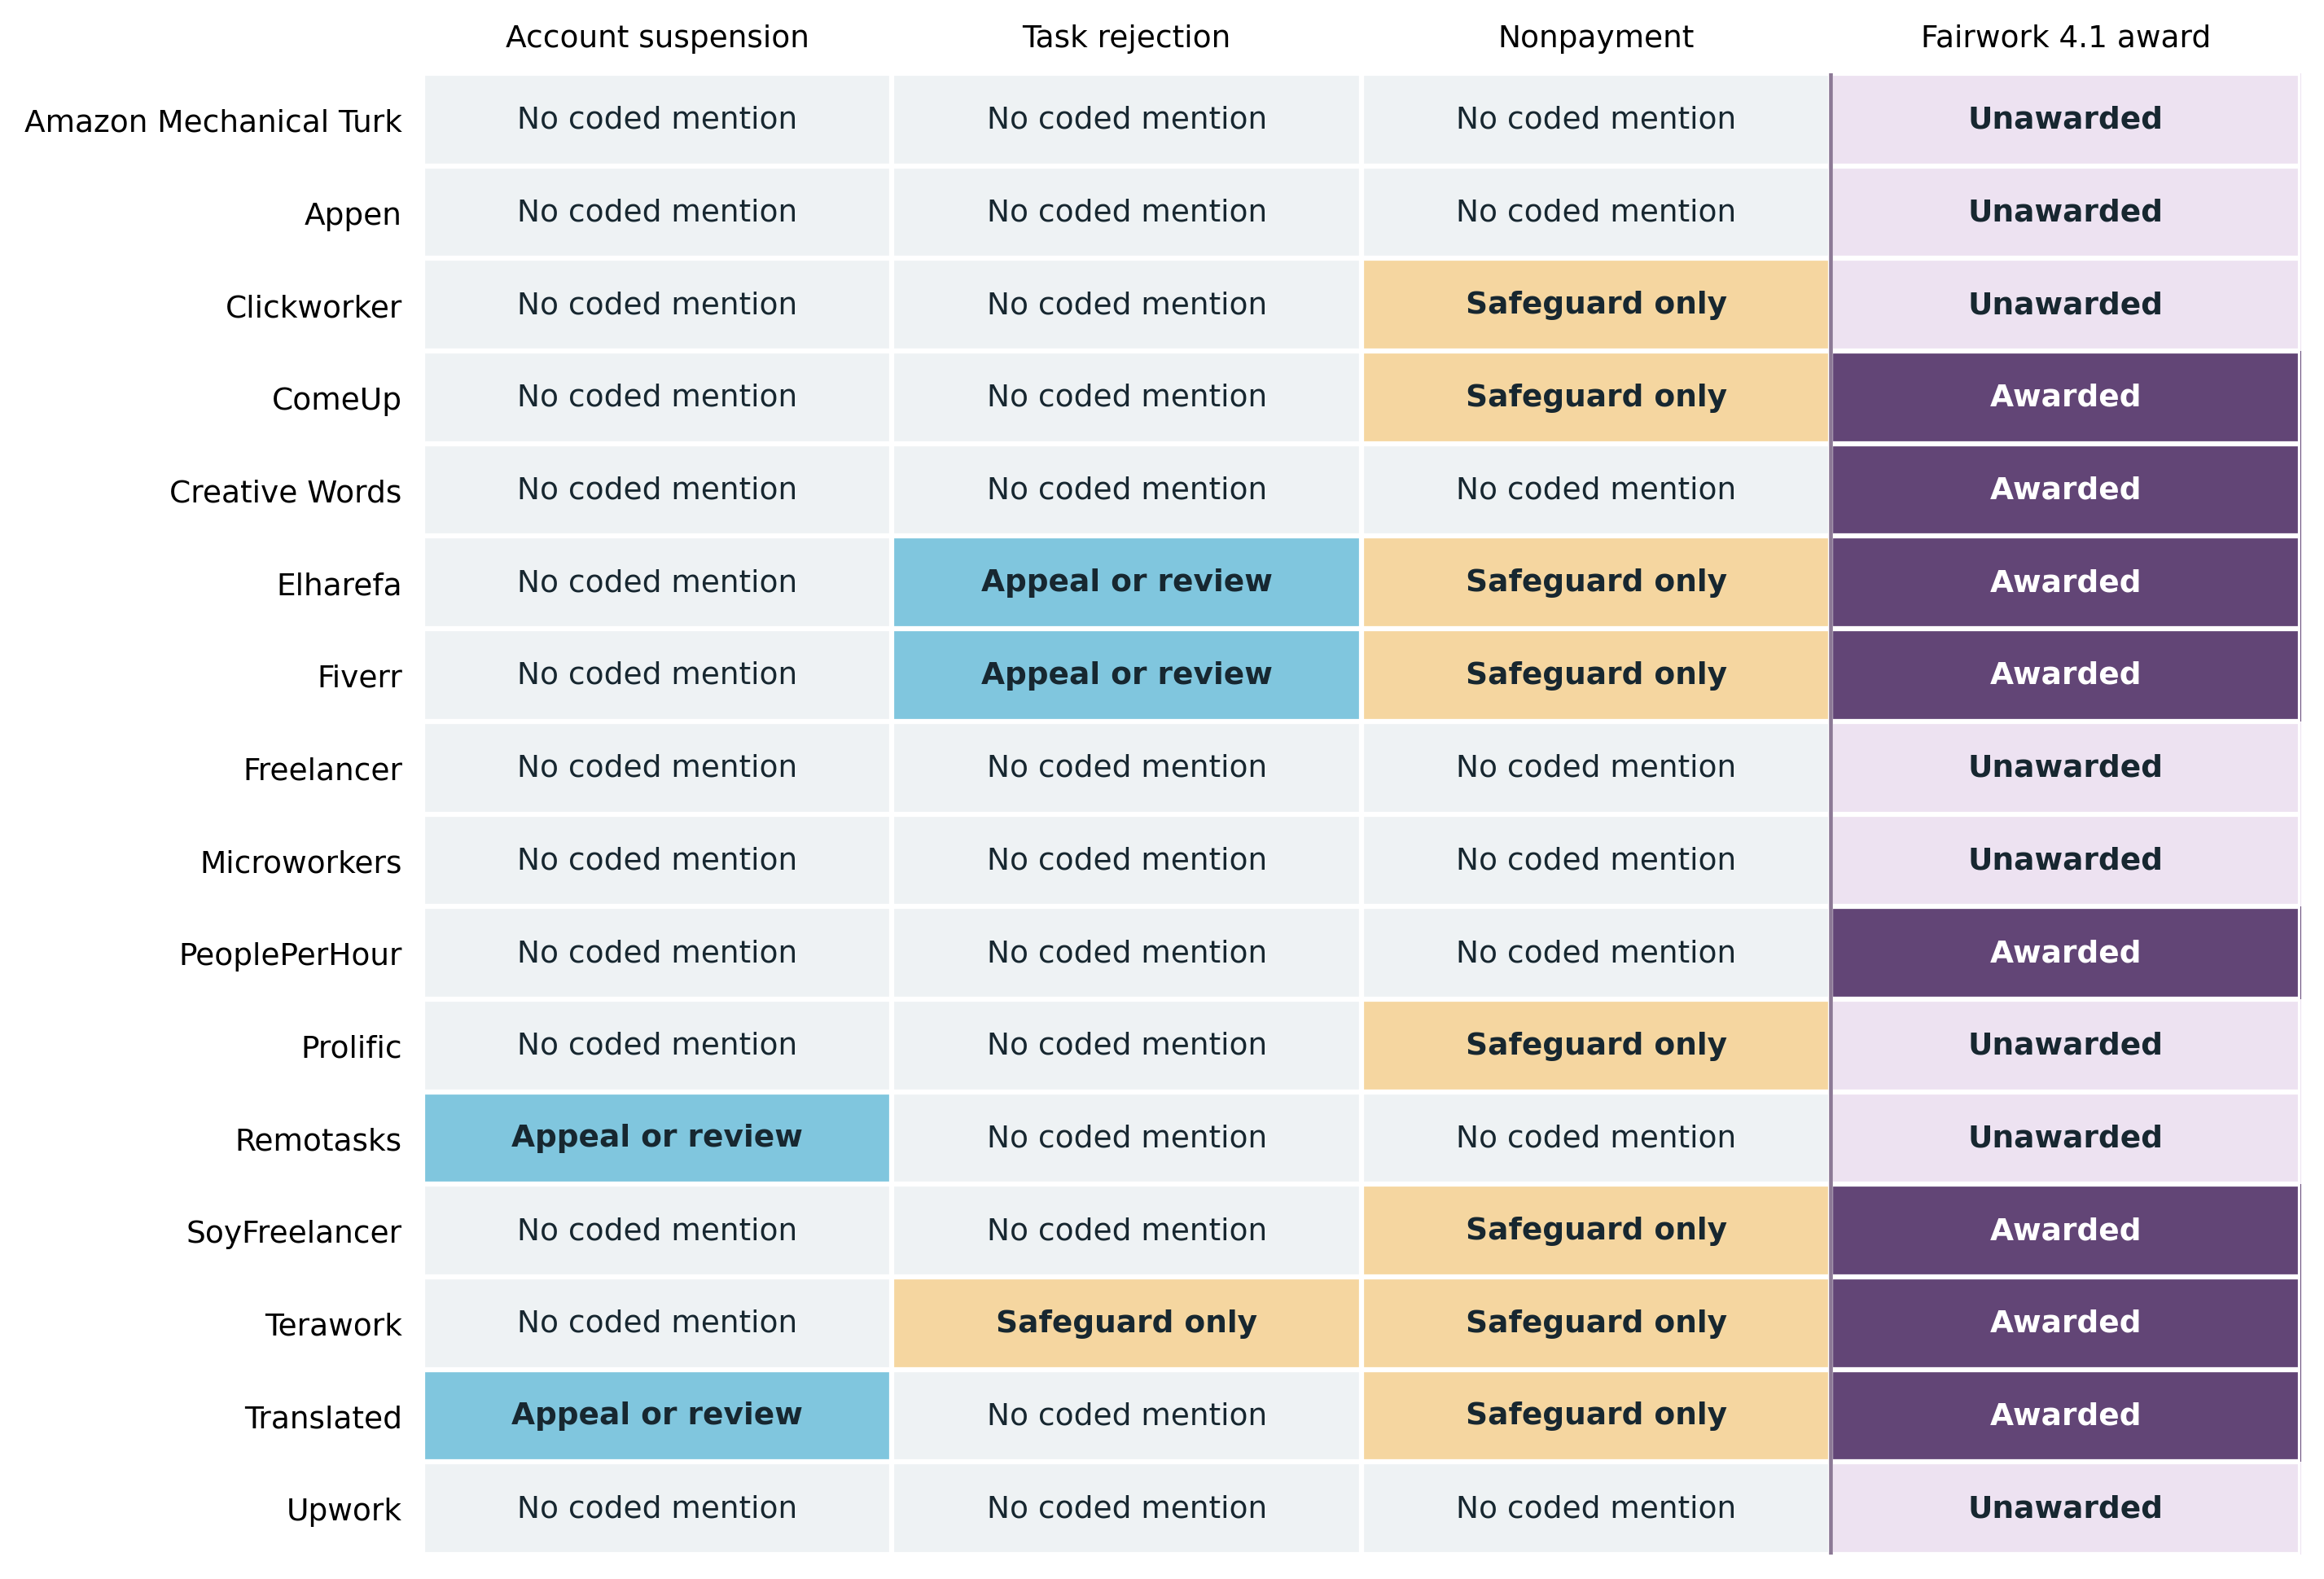

Evidence class,Decision,Appeal or review,Safeguard only,No coded mention,Platforms assessed,4.1 awarded overall,4.1 awarded with coded appeal or review
,Account suspension,2,0,14,16,8,1
,Task rejection,2,1,13,16,8,2
,Nonpayment,0,8,8,16,8,0


Platform,Account suspension,Task rejection,Nonpayment
Elharefa,No coded mention,Appeal route; Correction or remedy option; Named review or mediation actor,Payment protection
Fiverr,No coded mention,Appeal route,Payment protection
Terawork,No coded mention,Correction or remedy option,Payment protection
Translated,Access after lockout; Appeal route,No coded mention,Payment protection


Platform,Decision,Feature,Page,Evidence
Remotasks,Account suspension,Appeal route,31,Introduced deactivation support for disciplinary challenges.
Remotasks,Account suspension,Reason or explanation route,31,Deactivation support also describes obtaining further explanations.
Translated,Account suspension,Access after lockout,18,Deactivated workers can access the published procedure.
Translated,Account suspension,Appeal route,18,The report describes appeals by email and access to policy information after deactivation.
Clickworker,Nonpayment,Payment protection,12,The report identifies escrow among protections for completed work.
ComeUp,Nonpayment,Payment protection,12,The report identifies escrow among protections for completed work.
Elharefa,Nonpayment,Payment protection,12,The report identifies escrow among protections for completed work.
Fiverr,Nonpayment,Payment protection,25,The Fairwork worker profile describes the platform's escrow facility.
Prolific,Nonpayment,Payment protection,12,The report identifies escrow among protections for completed work.
SoyFreelancer,Nonpayment,Payment protection,12,The report identifies escrow among protections for completed work.


In [16]:
# Step 7 · Analyze decision-specific evidence for RQ2
# Compare three decision types across the 2025 roster and generate Figure 2 and S4–S6.

decisions = ["Account suspension", "Task rejection", "Nonpayment"]
full_grid = pd.MultiIndex.from_product([sorted(roster_25), decisions], names=["Platform", "Decision"])
direct = {"Appeal route", "Named review or mediation actor"}
only_safeguard = {"Payment protection", "Correction or remedy option"}
evidence_sets = safeguards.groupby(["Platform", "Decision"])["Feature"].agg(set).to_dict()

def coverage_class(features):
    if features & direct:
        return 2
    if features:
        assert features & only_safeguard
        return 1
    return 0

assert set(evidence_sets) <= set(full_grid)
assert set(safeguards["Feature"]) <= direct | only_safeguard | {
    "Reason or explanation route", "Access after lockout"
}
coverage = pd.Series(
    [coverage_class(evidence_sets.get(pair, set())) for pair in full_grid],
    index=full_grid, name="Evidence class",
).reset_index()
classes = {0: "No coded mention", 1: "Safeguard only", 2: "Appeal or review"}
awards_by_platform = ratings_25.set_index("Platform")["4.1 awarded"]
coverage["4.1 awarded"] = coverage["Platform"].map(awards_by_platform)
f2 = coverage.pivot(index="Platform", columns="Decision", values="Evidence class").reindex(columns=decisions)
award_label = "Fairwork 4.1 award"
f2[award_label] = 3 + awards_by_platform.reindex(f2.index)
matrix_labels = {**classes, 3: "Unawarded", 4: "Awarded"}
f2_labels = np.vectorize(matrix_labels.__getitem__)(f2.to_numpy())
fig = labeled_matrix(
    f2, f2_labels, ["#EEF2F4", "#F5D6A0", "#80C6DE", "#EDE2F1", "#624576"], 9.4, 6.35
)
fig.axes[0].axvline(2.5, color="#8B7895", linewidth=1.1)
exhibit_figure("Figure_2", "decision_specific_evidence",
               "Decision-specific evidence and the Fairwork 4.1 award",
               fig, coverage.assign(Interpretation=coverage["Evidence class"].map(classes)),
               "The first three columns summarize coded platform-specific passages. The right column shows Fairwork’s "
               "overall 4.1 award, which requires documented appeals for work rejections and disciplinary actions "
               "(2025 report, p. 41). No coded mention means no qualifying passage was entered for that decision.")
s4 = (coverage.groupby(["Decision", "Evidence class"]).size().unstack(fill_value=0)
      .reindex(index=decisions, columns=[2, 1, 0], fill_value=0).rename(columns=classes))
awarded = coverage[coverage["4.1 awarded"].eq(1)]
s4["Platforms assessed"] = len(roster_25)
s4["4.1 awarded overall"] = len(due_awards[2025])
s4["4.1 awarded with coded appeal or review"] = (
    awarded[awarded["Evidence class"].eq(2)].groupby("Decision").size().reindex(decisions, fill_value=0)
)
s4 = s4.reset_index()
exhibit_table("S4", "decision_type_coverage", "Decision-specific evidence and overlap with the 4.1 award", s4,
              "The first three count columns sum to 16 per decision. The overall award is the same benchmark in "
              "each row. The final column counts awarded platforms with a coded route or reviewer for that decision.")
contrast_rows = []
for platform in sorted(roster_25):
    contexts = {decision: evidence_sets.get((platform, decision), set()) for decision in decisions}
    if sum(bool(features) for features in contexts.values()) >= 2:
        contrast_rows.append({"Platform": platform, **{
            decision: "; ".join(sorted(features)) if features else "No coded mention"
            for decision, features in contexts.items()
        }})
s5 = pd.DataFrame(contrast_rows, columns=["Platform", *decisions])
exhibit_table("S5", "within_platform_contrasts", "Within-platform contrasts where at least two decision types are documented",
              s5, "Eligibility requires at least one coded feature in at least two contexts. Coverage may include a protective safeguard.")
s6 = safeguards.sort_values(["Decision", "Platform", "Feature"])
exhibit_table("S6", "decision_evidence_ledger", "Page-anchored decision and safeguard coding", s6,
              "Reason, access and reviewer details are coded only when explicitly identified in a decision-specific source.")


## RQ3 Published procedures and worker experience

Table 1 presents selected worker accounts alongside related procedural evidence. A broad procedure and an account involving a narrower decision receive an overlapping-scope label. A channel described inside a worker story and the associated experience are co-reported. Unmatched accounts are useful for identifying possible mechanisms, while timing and scope restrict stronger interpretation. The source does not link the pooled survey figure to individual cases.

In [17]:
# Step 8 · Compare worker accounts for RQ3
# Show observable barriers and match quality, and generate Table 1 and S7–S9.

def page_tag(page):
    return f" (p. {page})" if page != "" else ""

table1 = pd.DataFrame([{
    "Platform and edition": f"{row['Platform']}, {row['Edition']}",
    "Decision context": row["Decision"],
    "Procedure evidence": row["Mechanism evidence"] + page_tag(row["Mechanism page"]),
    "Worker experience": row["Worker evidence"] + page_tag(row["Worker page"]),
    "Evidence alignment": row["Match"],
} for row in worker_cases.to_dict("records")])
csv_export(worker_cases, "provenance", "worker_account_coding")
exhibit_table("Table_1", "worker_account_evidence",
              "Reported barriers and the scope of the corresponding procedure",
              table1, "The six rows are selected report observations. Some rows share a platform or narrator. "
              "The accounts illustrate reported barriers. A policy implementation assessment would require matching each episode to the policy in force at the time.")
s7 = (worker_cases.groupby(["Edition", "Match"], as_index=False)
      .agg(Observations=("Case", "size"), Cases=("Case", ", ".join)))
exhibit_table("S7", "evidence_alignment", "Alignment of policy and worker evidence", s7,
              "Co-reported and unmatched observations cannot independently validate a written policy.")
s8 = worker_cases[["Case", "Decision", "Barrier", "Platform", "Edition", "Worker page"]].sort_values(["Barrier", "Case"])
exhibit_table("S8", "barrier_by_context", "Reported barriers by decision context", s8,
              "Counts or row frequencies from this selected evidence should not be interpreted as population prevalence.")
s9 = pd.DataFrame([{
    "Edition": 2025, "Page": 21,
    "Survey measure": "Surveyed workers reported as unaware of an appeal process",
    "Reported share (%)": 40,
    "Denominator for this item": "Unspecified in the cited passage",
    "Level": "Pooled across platforms",
}])
exhibit_table("S9", "survey_context", "Fairwork survey context on appeal awareness", s9,
              "This is a published aggregate. The analysis does not infer a numerator or disaggregate by platform.")


Platform and edition,Decision context,Procedure evidence,Worker experience,Evidence alignment
"Fiverr, 2023",Task rejection and nonpayment,Fairwork describes a support route for objections to rejected work. (p. 13),A worker described an order dispute with withheld payment. Support deferred to negotiation with the client and the worker reported receiving nothing. (p. 22),Overlapping scope
"Fiverr, 2025",Account suspension,Fairwork describes disciplinary appeals and contact with a human representative for platforms that received 4.1. (p. 14),A worker described sudden account suspensions or removal of service listings without clear explanations. The account describes a general pattern. (p. 25),Overlapping scope
"Fiverr, 2025",Client dispute,The worker story identifies a formal platform mediation channel. (p. 25),The account described slow or impersonal resolution and raised concerns about bias. The report gives no case-level success rate. (p. 25),Co-reported mechanism and experience
"Appen, 2025",Delayed payment,The worker account establishes that a ticket channel was used. No separately matched payment appeal policy is coded.,"After the August 2024 CrowdGen migration, the worker received automated replies to repeated tickets. The worker reported receiving payment two weeks later. (p. 26)",Unmatched
"Appen, 2025",Client-platform deactivation,A support request was filed. The decision was made on a client platform and a matching review policy was not located in the report.,"The worker reported a September 2024 deactivation and received a generic list of potential grounds. Four months later, the worker still had no result from the investigation or specific reason. (p. 27)",Unmatched
"Elharefa, 2025",Client dispute,Fairwork describes a new team-mediated process for rejected work. (p. 17),A worker questioned the effectiveness of dispute resolution. The report does not link that account to a rejected-work case after the policy change. (p. 28),Overlapping scope


Edition,Match,Observations,Cases
2023,Overlapping scope,1,C01
2025,Co-reported mechanism and experience,1,C03
2025,Overlapping scope,2,"C02, C06"
2025,Unmatched,2,"C04, C05"


Case,Decision,Barrier,Platform,Edition,Worker page
C04,Delayed payment,Automated acknowledgement,Appen,2025,26
C02,Account suspension,Lack of an explanation,Fiverr,2025,25
C05,Client-platform deactivation,Lack of an explanation,Appen,2025,27
C01,Task rejection and nonpayment,No intervention,Fiverr,2023,22
C06,Client dispute,Perceived lack of effective recourse,Elharefa,2025,28
C03,Client dispute,Slow or impersonal review,Fiverr,2025,25


Edition,Page,Survey measure,Reported share (%),Denominator for this item,Level
2025,21,Surveyed workers reported as unaware of an appeal process,40,Unspecified in the cited passage,Pooled across platforms


## RQ4 Individual appeals and collective voice

Figure 3 combines two separately coded indicators for 2025. The individual indicator is Fairwork's full 4.1 award. The collective indicator records a documented public recognition statement, including SoyFreelancer’s statement on p. 33. Fairwork’s overall 5.1 award is listed separately in S10. S10 shows platform-level values. S11 tests whether the pattern is sensitive to changing either definition. S12 links the collective indicators to the report's own evidence.

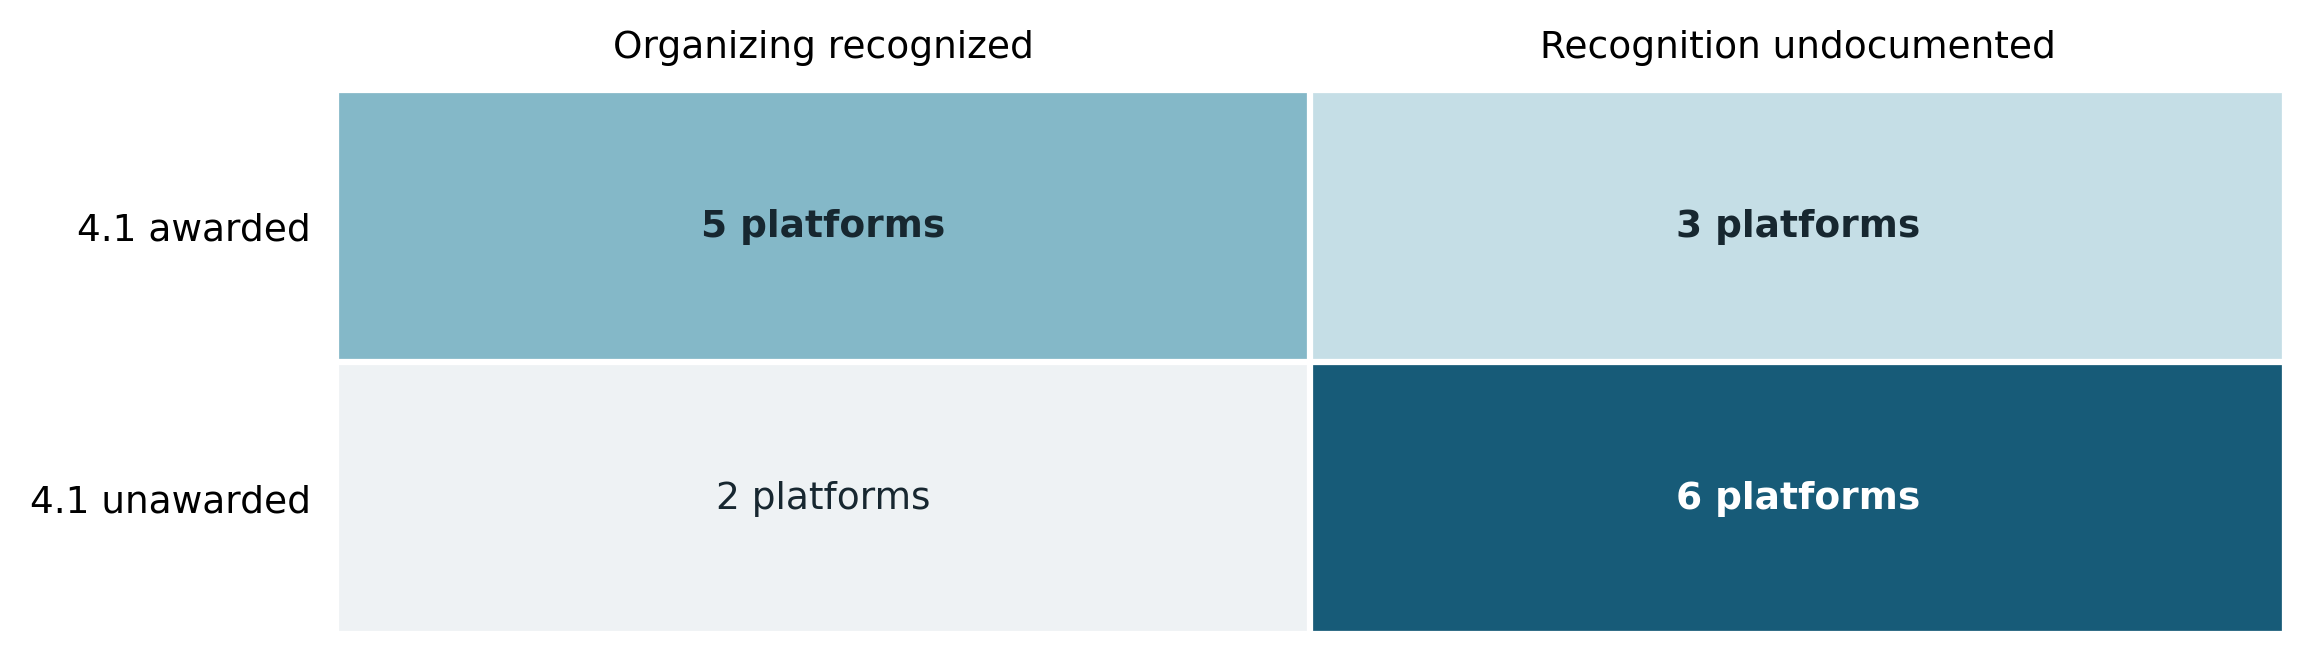

Platform,4.1 awarded,5.1 awarded,5.2 awarded,Organizing recognized,Bargaining explicitly referenced,Recognition page
Amazon Mechanical Turk,0,0,0,0,0,
Appen,0,1,0,1,0,15
Clickworker,0,0,0,0,0,
ComeUp,1,1,0,1,0,32
Creative Words,1,1,0,1,0,15
Elharefa,1,1,0,1,1,31
Fiverr,1,0,0,0,0,
Freelancer,0,0,0,0,0,
Microworkers,0,0,0,0,0,
PeoplePerHour,1,0,0,0,0,


Individual indicator,Collective indicator,Both,Individual only,Collective only,Neither documented
4.1 awarded,Organizing recognized,5,3,2,6
4.1 awarded,Bargaining explicitly referenced,2,6,0,8
4.1 or partial change,Organizing recognized,5,5,2,4
4.1 or partial change,Bargaining explicitly referenced,2,8,0,6


Platform,Page,Organizing recognized,Bargaining explicitly referenced,Evidence
Appen,15,1,0,Fairwork identifies freedom of association in the platform's modern slavery policy. This passage does not explicitly attribute bargaining language to Appen.
ComeUp,32,1,0,Terms acknowledge the right of workers to organize.
Creative Words,15,1,0,Fairwork reports that the company previously issued a similar public statement on organizing rights.
Elharefa,31,1,1,Terms add a public commitment to freedom of association and collective bargaining.
SoyFreelancer,33,1,0,The change log records a statement recognizing freedom of association and noting support for workers to organize collectively.
Translated,33,1,1,Public statement refers to freedom of association and collective agreements.
Upwork,15,1,0,Fairwork identifies freedom of association in the platform's modern slavery policy. This passage does not spell out bargaining language.


In [18]:
# Step 9 · Cross-tabulate appeals and formal recognition for RQ4
# Apply separate voice definitions, check classification sensitivity, and generate Figure 3 and S10–S12.

voice = ratings_25.merge(
    recognition[["Platform", "Page", "Organizing recognized", "Bargaining explicitly referenced"]],
    on="Platform", how="left", validate="one_to_one",
)
for column in ("Organizing recognized", "Bargaining explicitly referenced"):
    voice[column] = voice[column].fillna(0).astype(int)
voice["Page"] = voice["Page"].fillna("").map(lambda value: int(value) if value != "" else "")
voice = voice.rename(columns={"Page": "Recognition page"})
voice["4.1 or partial change"] = (voice["4.1 awarded"].eq(1) | voice["Platform"].isin(changes["Platform"])).astype(int)

def configurations(individual_column, collective_column):
    return (pd.crosstab(voice[individual_column], voice[collective_column])
            .reindex(index=[1, 0], columns=[1, 0], fill_value=0))

cross = configurations("4.1 awarded", "Organizing recognized")
display_cross = cross.set_axis(["4.1 awarded", "4.1 unawarded"], axis=0).set_axis(
    ["Organizing recognized", "Recognition undocumented"], axis=1)
counts = display_cross.to_numpy()
levels = np.unique(counts)
cross_codes = pd.DataFrame(np.searchsorted(levels, counts), index=display_cross.index, columns=display_cross.columns)
cross_labels = np.vectorize(lambda value: f"{value} {'platform' if value == 1 else 'platforms'}")(counts)
palette = ["#EEF2F4", "#C5DEE6", "#84B8C8"][:len(levels) - 1] + ["#175B78"]
fig = labeled_matrix(cross_codes, cross_labels, palette, 7.6, 2.1)
f3_data = (cross.rename_axis(index="4.1 awarded", columns="Organizing recognized")
           .stack().rename("Platforms").reset_index())
exhibit_figure("Figure_3", "individual_and_collective_voice",
               "Joint distribution of due process and public recognition of organizing rights",
               fig, f3_data, "2025 report roster, n = 16. Recognition concerns a published commitment. "
               "The recognition indicator includes a statement by SoyFreelancer, which did not earn 5.1. Fairwork awarded no platform its collective governance or bargaining threshold (5.2).")
s10 = voice[["Platform", "4.1 awarded", "5.1 awarded", "5.2 awarded", "Organizing recognized",
             "Bargaining explicitly referenced", "Recognition page"]].sort_values("Platform")
exhibit_table("S10", "voice_indicators_by_platform", "Individual and collective voice indicators by platform",
              s10, "A recognition value of 0 means no qualifying statement was documented in the coded passages.")
rows = []
for individual, collective in [
    ("4.1 awarded", "Organizing recognized"),
    ("4.1 awarded", "Bargaining explicitly referenced"),
    ("4.1 or partial change", "Organizing recognized"),
    ("4.1 or partial change", "Bargaining explicitly referenced"),
]:
    counts = configurations(individual, collective)
    rows.append({"Individual indicator": individual, "Collective indicator": collective,
                 "Both": counts.loc[1, 1], "Individual only": counts.loc[1, 0],
                 "Collective only": counts.loc[0, 1], "Neither documented": counts.loc[0, 0]})
s11 = pd.DataFrame(rows)
exhibit_table("S11", "voice_definition_sensitivity", "Sensitivity of the voice profiles to indicator choice", s11,
              "Partial change includes a reported 4.1 procedural change even if the rating was unawarded. "
              "Bargaining language is a policy-level indicator and differs from evidence of enacted bargaining.")
exhibit_table("S12", "recognition_evidence_ledger", "Source passages for formal organizing and bargaining language",
              recognition.sort_values("Platform"), "All entries are paraphrases of the 2025 report. The referenced policy's publication date may precede the report.")


## Results interpretation and reproducibility

The paired comparison holds the platform roster fixed. The analysis establishes what was documented in the reports. It does not measure successful appeals, worker well-being, enforcement frequency, or the causal effect of algorithmic management. Fairwork ratings already incorporate several evidence types, so the narrative extracts are complementary detail from the same assessment rather than an independent validation of its ratings. Two editions, uneven coverage of decision types and the absence of independently verified policy-to-episode matches restrict generalization. The package records the executed environment and source fingerprints. The audit documents checks against the reports and corrections to the initial manual coding. Independent recoding and adjudication are pending.

In [19]:
# Step 10 · Summarize findings and package all exhibits
# Check display and export coverage, write captions and provenance, and test the final ZIP.

# One primary exhibit per question plus twelve supplemental exhibits.
assert set(EXHIBITS) == {"Figure_1", "Figure_2", "Figure_3", "Table_1"} | {
    f"S{number}" for number in range(1, 13)
}
assert len([path for path in WRITTEN if path.suffix == ".pdf"]) == 3
assert len([path for path in WRITTEN if path.suffix == ".png"]) == 3
assert len([path for path in WRITTEN if path.parent.name == "tables"]) == 13
assert len([path for path in WRITTEN if path.parent.name == "plot_data"]) == 3
assert all(path.stat().st_size > 0 for path in WRITTEN)
assert len(coverage) == len(decisions) * len(roster_25)
assert not coverage.duplicated(["Platform", "Decision"]).any()
assert (s4[list(classes.values())].sum(axis=1) == len(roster_25)).all()
assert (s4["4.1 awarded with coded appeal or review"] <= s4["Appeal or review"]).all()
assert (coverage.groupby("Decision")["4.1 awarded"].sum() == len(due_awards[2025])).all()
assert cross.to_numpy().sum() == len(roster_25)
assert (s11.iloc[:, 2:].sum(axis=1) == len(roster_25)).all()

stable = paired["4.1 in 2023"].eq(paired["4.1 in 2025"])
unchanged = int(stable.sum())
with_change = int(paired.loc[stable, "A change reported"].sum())
direct_counts = s4.set_index("Decision")["Appeal or review"]
scope_limited = int(worker_cases["Match"].ne("Unmatched").sum())
findings = [
    f"RQ1: {unchanged} of {len(paired)} repeat platforms kept the same 4.1 award status. "
    f"The 2025 change log reports appeal changes for {with_change} of those platforms.",
    f"RQ2: Decision-specific appeal or review evidence was coded for "
    f"{direct_counts['Account suspension']} suspension, {direct_counts['Task rejection']} rejection, "
    f"and {direct_counts['Nonpayment']} nonpayment platform–decision combinations, out of 16 per decision. "
    f"Fairwork separately awarded overall 4.1 to {len(due_awards[2025])} platforms under a rubric that "
    "requires appeal procedures for work rejections. The decision-specific counts describe the coded passages.",
    f"RQ3: {scope_limited} of {len(worker_cases)} selected observations had overlapping or co-reported procedures. "
    "None was independently matched by incident date and policy in force.",
    f"RQ4: {cross.loc[1, 1]} platforms had both the 4.1 award and a documented public recognition statement. "
    f"{cross.loc[1, 0]} had only the award, {cross.loc[0, 1]} had only recognition, "
    f"and {cross.loc[0, 0]} had neither documented.",
]
readme = [
    "# Project 12 Fairwork Cloudwork results",
    "",
    "This archive contains three primary figures and one primary table, plus twelve supporting tables.",
    "Figures are provided as vector PDF and 300 dpi PNG. Tables and figure data are CSV.",
    "The manifest records the two source URLs, PDF fingerprints, and edition lengths.",
    "Manual ledgers contain page-cited paraphrases. The source PDFs are publicly available at the manifest URLs.",
    "Runtime versions and pinned direct dependencies are in provenance/run_environment.json and provenance/requirements.txt.",
    "",
    "## Reproduction and evidence status",
    "",
    "Open the accompanying notebook and run all cells. The notebook verifies both PDFs before extracting award and roster data.",
    "Use the notebook’s coding rules and exported ledgers to trace the reported counts to their source pages.",
    "The manual coding has been checked in a retrospective source audit. See provenance/evidence_source_audit.csv for corrections and inclusion decisions.",
    "Independent recoding, agreement and adjudication are pending.",
    "The selected worker accounts illustrate reported barriers. The corpus contains no independently date-matched policy and incident pairs in this analysis.",
    "",
    "## Results",
    "",
    *[f"- {finding}" for finding in findings],
    "",
    "## Exhibit captions",
    "",
]
for identifier, (title, note) in EXHIBITS.items():
    readme.extend([f"### {identifier}. {title}", "", note, ""])
readme_path = remember(RESULT_ROOT / "README.md")
readme_path.write_text("\n".join(readme) + "\n", encoding="utf-8")

archive = WORK / "project12_fairwork_results.zip"
members = {path.relative_to(WORK).as_posix() for path in WRITTEN}
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED, compresslevel=6) as bundle:
    for path in sorted(WRITTEN):
        bundle.write(path, arcname=path.relative_to(WORK))
with zipfile.ZipFile(archive) as bundle:
    assert set(bundle.namelist()) == members
    assert bundle.testzip() is None

for finding in findings:
    print(finding)
print(f"Verified archive: {archive.name} ({len(members)} files).")
display(FileLink(os.path.relpath(archive)))


RQ1: 14 of 14 repeat platforms kept the same 4.1 award status. The 2025 change log reports appeal changes for 5 of those platforms.
RQ2: Decision-specific appeal or review evidence was coded for 2 suspension, 2 rejection, and 0 nonpayment platform–decision combinations, out of 16 per decision. Fairwork separately awarded overall 4.1 to 8 platforms under a rubric that requires appeal procedures for work rejections. The decision-specific counts describe the coded passages.
RQ3: 4 of 6 selected observations had overlapping or co-reported procedures. None was independently matched by incident date and policy in force.
RQ4: 5 platforms had both the 4.1 award and a documented public recognition statement. 3 had only the award, 2 had only recognition, and 6 had neither documented.
Verified archive: project12_fairwork_results.zip (29 files).


/kaggle/working/project12_fairwork_results.zip